# Análisis Exploratorio de los Datos

Ciencia de Datos · UTN FRM · 2026

Este notebook recorre el dataset canónico de la materia siguiendo **las mismas seis
fases que define la teórica**, en el mismo orden: inspección inicial, análisis
univariado, análisis bivariado, análisis de calidad, análisis temporal y generación
de hipótesis.

El dataset es el que produjo el DAG `fifa_ingest` de la Unidad 1:
`fifa_canonico_2026-07-23.csv`, con 18.936 jugadores y 90 columnas. La primera celda
lo descarga sola; no hay que subir nada a mano.

Se corre de arriba hacia abajo.

# Sección 1: Inspección inicial del dataset

El objetivo de esta fase es armarse un mapa mental del dataset antes de calcular
nada: cuántas observaciones hay, qué mide cada columna, de qué tipo es cada variable
y en qué formato está guardado todo.

### Cargar el dataset

Una fila es un jugador en un momento dado. Las columnas mezclan identidad, club,
características físicas y atributos técnicos.

In [ ]:
# El dataset se baja del Drive de la cátedra la primera vez que se corre el notebook
import os

ARCHIVO  = "fifa_canonico_2026-07-23.csv"
ID_DRIVE = "1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

Downloading...
From: https://drive.google.com/uc?id=1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls
To: /content/fifa_canonico_2026-07-23.csv
100% 9.56M/9.56M [00:00<00:00, 31.0MB/s]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(ARCHIVO, low_memory=False)

In [ ]:
# Dimensiones: observaciones y variables
df.shape

(18936, 90)

### Las primeras filas

Con 90 columnas, `head()` completo no entra en pantalla. Conviene pedir un subconjunto
que permita reconocer de qué habla cada fila.

In [ ]:
# Un vistazo con las columnas más reconocibles
df[["short_name", "age", "club_name", "league_name", "best_position", "overall", "value_eur"]].head()

,short_name,age,club_name,league_name,best_position,overall,value_eur
0,P. Billing,29,FC Midtjylland,Superliga,CM,76,7500000
1,A. Şimşir,23,FC Midtjylland,Superliga,CAM,76,12000000
2,G. Links,26,Aarhus Gymnastikforening,Superliga,LM,75,6000000
3,M. Elyounoussi,30,FC København,Superliga,RM,75,5500000
4,D. Kotarski,25,FC København,Superliga,GK,75,6000000


### Tipos de datos

pandas infiere un tipo por columna al leer el CSV. El recuento por tipo es la forma
más rápida de saber con qué se está trabajando: acá casi todo es entero, y lo que
queda como texto son los nombres, las categorías y las fechas.

In [ ]:
# Cuántas columnas hay de cada tipo
df.dtypes.value_counts()

,count
int64,71
object,19


### Noventa columnas no se leen de a una

El nombre de las columnas de este dataset tiene estructura: casi todas empiezan con
un prefijo que dice a qué familia pertenecen. Aprovecharlo convierte una lista de 90
nombres en un mapa de diez grupos.

In [ ]:
# Familias de columnas, según el prefijo anterior al primer guión bajo
df.columns.str.split("_").str[0].value_counts()

,count
total,8
club,7
skill,6
mentality,6
player,5
power,5
goalkeeping,5
attacking,5
movement,5
defending,4


In [ ]:
# Las columnas de una familia concreta
df.columns[df.columns.str.startswith("goalkeeping")].tolist()

['goalkeeping_diving',
 'goalkeeping_handling',
 'goalkeeping_kicking',
 'goalkeeping_positioning',
 'goalkeeping_reflexes']

### Los cuatro tipos de variable

La teórica distingue variables numéricas, categóricas, temporales y de texto libre.
El dataset tiene ejemplos de los cuatro, y las numéricas se dividen además en
continuas y discretas, y las categóricas en nominales y ordinales.

In [ ]:
# Un ejemplo de cada tipo de variable
ejemplos = ["value_eur", "age", "best_position", "international_reputation", "club_joined_date", "player_traits"]
df[ejemplos].head()

,value_eur,age,best_position,international_reputation,club_joined_date,player_traits
0,7500000,29,CM,1,2025-08-26,NaN
1,12000000,23,CAM,1,2020-02-17,"Finesse Shot, Whipped Pass, Inventive, Technic..."
2,6000000,26,LM,1,2019-09-01,"Dead Ball, Whipped Pass, Inventive, Technical,..."
3,5500000,30,RM,1,2023-07-27,"Precision Header, Gamechanger, Incisive Pass, ..."
4,6000000,25,GK,1,2025-07-09,Footwork


In [ ]:
# Cuántos valores distintos toma cada una
df[ejemplos].nunique()

,0
value_eur,257
age,28
best_position,15
international_reputation,5
club_joined_date,1942
player_traits,2090


El número de valores distintos ya separa los tipos: `international_reputation` toma
cinco valores ordenados —es ordinal—, `best_position` toma quince sin orden natural
—es nominal—, y `player_traits` toma más de dos mil, lo que es la firma del texto
libre.

In [ ]:
# Los valores de una variable ordinal, con su frecuencia
df["international_reputation"].value_counts().sort_index()

,count
international_reputation,
1,18121
2,258
3,489
4,51
5,17


### Formato y estructura: esto es una foto, no una película

Tres columnas del dataset tienen un solo valor en las 18.936 filas. No sirven para
distinguir jugadores, pero dicen algo importante sobre el archivo: es un **snapshot**
tomado en una fecha. Eso va a condicionar toda la fase temporal.

In [ ]:
# Columnas que no varían en todo el dataset
df.columns[df.nunique(dropna=False) == 1].tolist()

['fifa_version', 'fifa_update', 'fifa_update_date']

In [ ]:
# Qué versión y qué fecha describe ese snapshot
df[["fifa_version", "fifa_update", "fifa_update_date"]].iloc[0]

,0
fifa_version,26
fifa_update,46
fifa_update_date,2026-07-23


### Las quince posiciones, en castellano

`best_position` usa las siglas del juego, en inglés. Son quince y no se simplifican: cada
una describe un puesto distinto. Para que las tablas y los gráficos que siguen se lean sin
traducir mentalmente, agregamos una columna con el nombre en castellano.

In [ ]:
POSICIONES = {
    "GK":  "Arquero",
    "CB":  "Defensor central",
    "RB":  "Lateral derecho",        "LB":  "Lateral izquierdo",
    "RWB": "Carrilero derecho",      "LWB": "Carrilero izquierdo",
    "CDM": "Mediocampista defensivo",
    "CM":  "Mediocampista central",  "CAM": "Mediocampista ofensivo",
    "RM":  "Mediocampista derecho",  "LM":  "Mediocampista izquierdo",
    "RW":  "Extremo derecho",        "LW":  "Extremo izquierdo",
    "ST":  "Delantero centro",       "CF":  "Segundo delantero",
}

df["best_position_explained"] = df["best_position"].map(POSICIONES)

In [ ]:
# Que ninguna posición haya quedado sin traducir
df["best_position_explained"].isna().sum()

np.int64(0)

In [ ]:
# La sigla y su nombre, una fila por posición
df[["best_position", "best_position_explained"]].drop_duplicates().sort_values("best_position")

,best_position,best_position_explained
1,CAM,Mediocampista ofensivo
5,CB,Defensor central
10,CDM,Mediocampista defensivo
505,CF,Segundo delantero
0,CM,Mediocampista central
4,GK,Arquero
27,LB,Lateral izquierdo
2,LM,Mediocampista izquierdo
192,LW,Extremo izquierdo
99,LWB,Carrilero izquierdo


# Sección 2: Análisis univariado

Acá se mira cada variable por separado: cómo se comporta, qué valores toma, qué forma
tiene su distribución y si hay valores atípicos. Es la fase donde se aplican las
medidas de estadística descriptiva.

### Las medidas de resumen

`describe()` da de una vez las medidas de tendencia central y de dispersión que pide
la teórica: media, mediana —el percentil 50—, desviación estándar, mínimo, máximo y
cuartiles.

In [ ]:
numericas = ["age", "height_cm", "weight_kg", "overall", "potential", "value_eur", "wage_eur"]
df[numericas].describe().round(1)

,age,height_cm,weight_kg,overall,potential,value_eur,wage_eur
count,18936.0,18936.0,18936.0,18936.0,18936.0,18936.0,18936.0
mean,24.7,182.1,75.1,65.7,71.1,2959712.2,9948.3
std,4.8,6.9,6.9,7.0,6.4,7984709.0,19917.8
min,16.0,155.0,47.0,47.0,48.0,0.0,500.0
25%,21.0,177.0,70.0,61.0,67.0,475000.0,1000.0
50%,24.0,182.0,75.0,66.0,71.0,1000000.0,3000.0
75%,28.0,187.0,80.0,70.0,75.0,2100000.0,10000.0
max,44.0,210.0,105.0,91.0,95.0,172500000.0,610000.0


### Las medidas de forma

Tendencia central y dispersión no alcanzan para describir una distribución. La **asimetría**
mide hacia qué lado se estira la cola: vale 0 cuando la distribución es simétrica, es positiva
cuando la cola larga cae a la derecha —unos pocos valores muy por encima del resto— y negativa
cuando cae a la izquierda. La **curtosis** mide cuánto pesan las colas comparadas con una
campana normal: pandas la devuelve centrada en 0, así que cerca de 0 la distribución tiene
colas parecidas a las de una normal, y cuanto más alta, más valores extremos hay de los que
una normal predeciría.

In [ ]:
# Asimetría y curtosis de las mismas columnas
df[numericas].agg(["skew", "kurt"]).round(2).T

,skew,kurt
age,0.43,-0.47
height_cm,-0.04,-0.33
weight_kg,0.22,0.05
overall,0.01,0.10
potential,0.00,-0.00
value_eur,8.54,107.26
wage_eur,6.61,87.03


Los números son elocuentes. `overall` tiene asimetría 0,01 y curtosis 0,10: simétrica y con
colas normales, una campana casi perfecta que no es una propiedad del fútbol sino una decisión
de diseño del juego. `value_eur` tiene asimetría 8,54 y curtosis 107: la cola derecha se estira
muchísimo y pesa muchísimo, porque unos pocos jugadores valen cien veces la mediana.

### La forma se ve en el histograma

El histograma muestra de un vistazo lo que las medidas de forma resumen en un número.
Tres casos distintos: una campana, una cola larguísima y una distribución con dos
picos separados por un hueco.

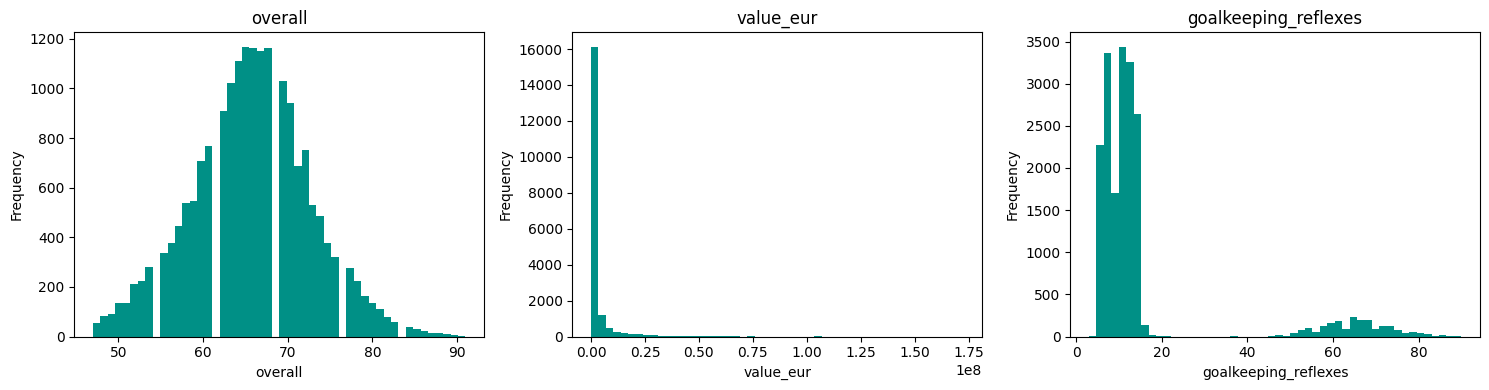

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["overall", "value_eur", "goalkeeping_reflexes"]):
    df[col].plot.hist(bins=50, ax=ax, color="#009086", title=col)
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

El tercero merece atención: `goalkeeping_reflexes` no está sesgada, está **partida**.
Son dos poblaciones distintas —arqueros y jugadores de campo— guardadas en la misma
columna. La media global cae en el medio y no describe a ninguna de las dos.

In [ ]:
# Cuánta gente hay en cada tramo de la columna partida
pd.cut(df["goalkeeping_reflexes"], bins=[0, 20, 40, 60, 100]).value_counts().sort_index()

,count
goalkeeping_reflexes,
"(0, 20]",16827
"(20, 40]",2
"(40, 60]",595
"(60, 100]",1512


### Valores extremos

El boxplot resume la distribución y marca como atípico todo lo que se aleja del rango
intercuartílico. En una variable tan sesgada como el valor de mercado, los atípicos
son legítimos: son las estrellas, no errores de carga.

In [ ]:
# Percentiles altos, donde se concentra la cola
df["value_eur"].describe(percentiles=[.5, .75, .9, .99]).round(0)

,value_eur
count,18936.0
mean,2959712.0
std,7984709.0
min,0.0
50%,1000000.0
75%,2100000.0
90%,5500000.0
99%,36000000.0
max,172500000.0


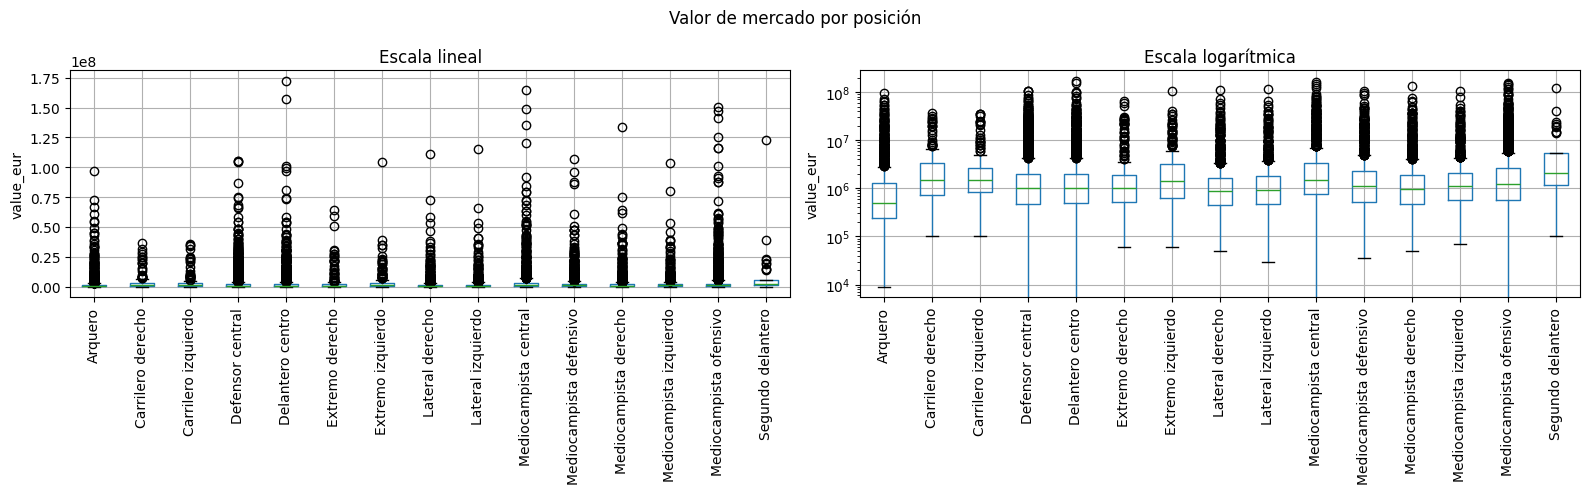

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, escala in zip(axes, ["Escala lineal", "Escala logarítmica"]):
    df.boxplot(column="value_eur", by="best_position_explained", ax=ax, rot=90)
    ax.set_title(escala); ax.set_xlabel(""); ax.set_ylabel("value_eur")

axes[1].set_yscale("log")
fig.suptitle("Valor de mercado por posición")
plt.tight_layout()
plt.show()

En escala lineal casi todo se aplasta contra el piso y sólo se ven los atípicos; en escala
logarítmica se distingue el cuerpo de cada distribución y se puede comparar posición contra
posición. Es el remedio estándar para una variable con asimetría 8,5. La escala logarítmica no
puede dibujar los once jugadores con valor cero, que aparecen en la sección 4.

### Variables categóricas: frecuencias

Para una categórica no hay media ni desviación: hay frecuencia absoluta, frecuencia relativa y
moda. `value_counts()` da las dos primeras según se le pida o no `normalize`, y la moda es
simplemente la primera fila de la tabla.

In [ ]:
# Frecuencia absoluta y relativa de cada posición
pd.DataFrame({"jugadores":  df["best_position_explained"].value_counts(),
              "proporción": df["best_position_explained"].value_counts(normalize=True).round(3)})

,jugadores,proporción
best_position_explained,,
Defensor central,3769,0.199
Delantero centro,2641,0.139
Mediocampista ofensivo,2570,0.136
Arquero,2106,0.111
Mediocampista derecho,1518,0.080
Mediocampista defensivo,1289,0.068
Mediocampista central,1193,0.063
Lateral derecho,1064,0.056
Lateral izquierdo,1003,0.053


### Las categorías menos frecuentes

La cola de una categórica importa tanto como la cabeza: son los grupos donde cualquier
promedio que se calcule después va a estar sostenido por muy pocos casos.

In [ ]:
# Las ligas con menos jugadores en el dataset
df["league_name"].value_counts().tail(5)

,count
league_name,
Nemzeti Bajnokság I,34
1. Division,31
Thai League 1,30
Premyer Liqa,26
Veikkausliiga,25


# Sección 3: Análisis bivariado

Una variable por vez no muestra relaciones. Esta fase cruza de a dos para detectar
dependencias, tendencias y agrupamientos naturales. Hay dos cruces básicos: una
numérica contra una categórica, y dos numéricas entre sí.

### Una numérica contra una categórica

Se compara el comportamiento de la variable numérica dentro de cada categoría. La
mediana por grupo es el resumen más robusto, y el boxplot muestra además cuánto se
solapan los grupos.

In [ ]:
# Altura mediana según la posición
df.groupby("best_position_explained")["height_cm"].median().sort_values(ascending=False)

,height_cm
best_position_explained,
Arquero,189.0
Defensor central,187.0
Delantero centro,184.0
Mediocampista central,180.0
Mediocampista defensivo,180.0
Segundo delantero,179.5
Carrilero izquierdo,179.0
Lateral derecho,179.0
Lateral izquierdo,178.0


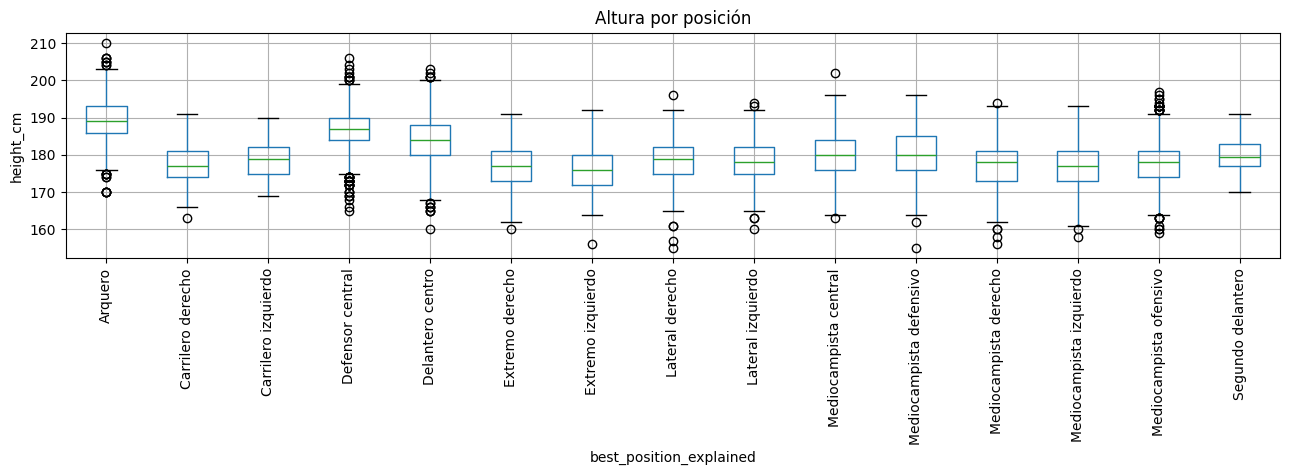

In [ ]:
df.boxplot(column="height_cm", by="best_position_explained", figsize=(13, 5), rot=90)
plt.title("Altura por posición")
plt.suptitle("")
plt.ylabel("height_cm")
plt.tight_layout()
plt.show()

### Dos numéricas: el gráfico de dispersión

El scatter es la forma de ver si dos variables numéricas se mueven juntas y, sobre
todo, **de qué forma**. Acá se ve que a mayor overall mayor valor, pero que la
relación no es una recta: se dispara en la punta.

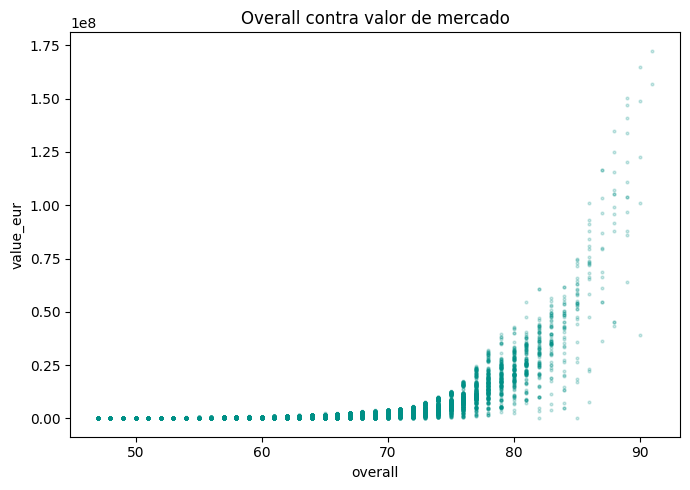

In [ ]:
df.plot.scatter(x="overall", y="value_eur", s=4, alpha=.2, figsize=(7, 5),
                color="#009086", title="Overall contra valor de mercado")
plt.tight_layout()
plt.show()

### La correlación mide rectas, no relaciones

El coeficiente de Pearson mide cuán bien se ajusta una **recta**. Spearman mide si
una crece cuando la otra crece, sin exigir que sea una recta. Cuando los dos números
son muy distintos, la relación existe pero es curva.

In [ ]:
# La misma pareja de variables, medida de dos maneras
pd.Series({"pearson":  df["overall"].corr(df["value_eur"]),
           "spearman": df["overall"].corr(df["value_eur"], method="spearman")}).round(3)

,0
pearson,0.550
spearman,0.882


Pearson da 0,55 y Spearman 0,88. La relación es fuerte y casi perfectamente monótona,
pero la recta la captura mal. Quedarse sólo con Pearson habría llevado a concluir que
el overall explica el valor a medias, y no es así.

### La matriz de correlación

Cruzar todas las numéricas de a pares a mano es inviable. `corr()` devuelve la matriz completa,
y `background_gradient` la pinta: con siete variables ya cuesta leer 49 números sueltos, y el
color deja ver de un vistazo qué bloque va junto y qué bloque va en contra.

In [ ]:
# La matriz, coloreada: rojo correlación negativa, azul positiva
seis = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]
df[seis + ["overall"]].corr().round(2).style.background_gradient(cmap="RdBu", vmin=-1, vmax=1)

,pace,shooting,passing,dribbling,defending,physic,overall
pace,1.000000,0.340000,0.320000,0.530000,-0.130000,-0.020000,0.330000
shooting,0.340000,1.000000,0.680000,0.770000,-0.380000,0.070000,0.470000
passing,0.320000,0.680000,1.000000,0.860000,0.190000,0.260000,0.730000
dribbling,0.530000,0.770000,0.860000,1.000000,-0.030000,0.160000,0.720000
defending,-0.130000,-0.380000,0.190000,-0.030000,1.000000,0.520000,0.390000
physic,-0.020000,0.070000,0.260000,0.160000,0.520000,1.000000,0.610000
overall,0.330000,0.470000,0.730000,0.720000,0.390000,0.610000,1.000000


Dos lecturas salen solas. `passing` y `dribbling` correlacionan 0,86 entre sí: miden
casi lo mismo. Y `defending` correlaciona **negativo** con `shooting`, −0,38: no es un
error, es que el juego reparte puntos entre perfiles opuestos.

### Correlación contra un objetivo categórico

`corr()` sólo sirve entre numéricas. Para medir cuánto se relaciona una variable numérica con
una **categórica** —que es lo que nos importa, porque el objetivo del modelo de la Unidad 3 es
la posición— se usa la **razón de correlación**, escrita η². Responde: ¿qué proporción de la
variación de la numérica se explica por saber a qué categoría pertenece? Va de 0 a 1.

In [ ]:
def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    grupos = df.groupby(categoria)[numerica]
    media = df[numerica].mean()
    entre = (grupos.count() * (grupos.mean() - media) ** 2).sum()
    total = ((df[numerica] - media) ** 2).sum()
    return entre / total

In [ ]:
# Qué tanto explica la posición a cada variable
candidatas = ["goalkeeping_reflexes", "defending_standing_tackle", "attacking_finishing",
              "mentality_interceptions", "attacking_crossing", "movement_sprint_speed",
              "height_cm", "power_strength", "age", "overall", "value_eur"]

pd.Series({c: eta2(c, "best_position") for c in candidatas}).sort_values(ascending=False).round(3)

,0
goalkeeping_reflexes,0.952
defending_standing_tackle,0.777
attacking_finishing,0.776
mentality_interceptions,0.742
attacking_crossing,0.675
movement_sprint_speed,0.625
height_cm,0.409
power_strength,0.332
age,0.054
overall,0.024


El ranking es la primera respuesta seria a «qué variables sirven para predecir la posición».
`goalkeeping_reflexes` explica el 95 % de su propia variación con sólo saber el puesto, y detrás
vienen los atributos de marca y de definición. Abajo del todo, `overall` explica 0,024 y
`value_eur` 0,012: **la posición no dice nada sobre cuán bueno ni cuán caro es un jugador**, y
por eso esas dos columnas no aportan al modelo de la Unidad 3.

# Sección 4: Análisis de calidad de datos

Esta fase busca los problemas que van a arruinar el modelado si nadie los mira:
faltantes, duplicados, inconsistencias de codificación y valores extremos. El dataset
salió de un pipeline que corrió sin errores, así que la pregunta es la incómoda:
limpio, ¿según quién?

### Valores faltantes: cuántos y dónde

In [ ]:
# Columnas con valores nulos y su porcentaje
nulos = df.isna().sum()
pd.DataFrame({"nulos": nulos[nulos > 0], "porcentaje": (100 * nulos[nulos > 0] / len(df)).round(1)})

,nulos,porcentaje
club_loan_end_date,17337,91.6
player_traits,10827,57.2


Sólo dos columnas de noventa. Pero el porcentaje no alcanza para decidir qué hacer:
la teórica pide también **la causa**. Un criterio del tipo «borro toda columna con más
de la mitad de nulos» mataría `club_loan_end_date` sin preguntar por qué falta.

In [ ]:
# Quiénes son los que sí tienen fecha de fin de préstamo
df.loc[df["club_loan_end_date"].notna(), ["short_name", "club_name", "club_loan_end_date"]].head()

,short_name,club_name,club_loan_end_date
9,B. Godfrey,Brøndby IF,2026-06-30
26,A. Lind,FC Nordsjælland,2026-06-30
38,A. Richardson,FC København,2026-06-30
67,R. Carstensen,Aarhus Gymnastikforening,2026-06-30
101,T. Klidje,Randers FC,2026-06-30


Son los jugadores cedidos a préstamo. El resto no tiene fecha porque no está cedido:
el nulo no es un dato que falta, es un «no corresponde».

Con `player_traits` la causa aparece cruzándolo contra otra columna del propio dataset.

In [ ]:
# ¿El nulo de player_traits coincide con no tener ningún playstyle?
pd.crosstab(df["player_traits"].isna(), df["playstyles_count"] == 0)

playstyles_count,False,True
player_traits,,
False,8109,0
True,0,10827


Las dos celdas cruzadas están en cero: las 10.827 filas con `player_traits` nulo son
exactamente las que tienen `playstyles_count` igual a cero. El nulo codifica «este
jugador no tiene ningún rasgo especial». Imputarlo inventaría rasgos.

### Duplicados: primero hay que elegir la clave

Deduplicar sin decidir qué cuenta como «la misma fila» borra datos buenos. El
resultado cambia por completo según la clave que se use.

In [ ]:
# La misma pregunta con tres claves distintas
pd.Series({"por player_id":            df.duplicated(subset=["player_id"]).sum(),
           "por fila completa":        df.duplicated().sum(),
           "por short_name + club":    df.duplicated(subset=["short_name", "club_name"]).sum()})

,0
por player_id,0
por fila completa,0
por short_name + club,21


In [ ]:
# Las filas que la tercera clave daría por repetidas
repetidos = df[df.duplicated(subset=["short_name", "club_name"], keep=False)]
repetidos[["player_id", "short_name", "long_name", "club_name", "age"]].sort_values("short_name").head(6)

,player_id,short_name,long_name,club_name,age
14438,80561,A. Dumitru,Andrei Dumitru,FC Botoşani,18
14430,275227,A. Dumitru,Antonio Dumitru,FC Botoşani,20
18831,73732,A. Saji,Alan Saji,SC Delhi,19
18703,270742,A. Saji,Alex Saji,SC Delhi,25
18563,223760,A. Singh,Amrinder Singh,Odisha FC,32
18892,276143,A. Singh,Ashangbam Singh Singh,Odisha FC,21


Andrei Dumitru y Antonio Dumitru son dos personas distintas del mismo club que comparten
el nombre abreviado. No son duplicados: deduplicar por esa clave habría borrado 21
jugadores reales.

### Inconsistencias de codificación

La teórica las describe como errores de codificación, cambios de nomenclatura o
formatos mezclados. Son las más difíciles de ver, porque no rompen nada. Esta es la
más cara del dataset.

In [ ]:
# ¿Cuántas ligas hay, según se cuenten por id o por nombre?
pd.Series({"league_id": df["league_id"].nunique(), "league_name": df["league_name"].nunique()})

,0
league_id,52
league_name,43


In [ ]:
# Nombres de liga que corresponden a más de una liga
ids_por_nombre = df.groupby("league_name")["league_id"].nunique()
ids_por_nombre[ids_por_nombre > 1].sort_values(ascending=False)

,league_id
league_name,
Super League,4
Pro League,3
Premier League,2
Bundesliga,2
Primera Division,2
Serie A,2


In [ ]:
# Qué esconde uno de esos nombres
sl = df[df["league_name"] == "Super League"]
sl.groupby(["league_id", "league_country"]).agg(
    jugadores=("player_id", "size"), overall_medio=("overall", "mean")).round(2)

,,jugadores,overall_medio
league_id,league_country,,
63,Greece,122,71.76
189,Switzerland,357,63.47
2012,China PR,430,58.10
2149,India,365,55.38


In [ ]:
# El promedio, según se agrupe por el nombre o por el identificador
por_id = sl.groupby("league_id")["overall"].mean()
pd.Series({"agrupando por league_name": sl["overall"].mean(),
           "la más alta de las cuatro":  por_id.max(),
           "la más baja de las cuatro":  por_id.min()}).round(2)

,0
agrupando por league_name,60.13
la más alta de las cuatro,71.76
la más baja de las cuatro,55.38


Agrupado por nombre, «Super League» da un overall medio de 60,1. Adentro hay cuatro
ligas que van de 55,4 a 71,8, y el promedio cae donde no hay nadie. El código no
falla, devuelve un número plausible, y está mal. **Se agrupa por identificadores, no
por nombres.**

### Formatos mezclados

`body_type` guarda dos cosas en un solo string: la contextura y un rango de altura
entre paréntesis. Cuando una columna repite información que ya está en otra, hay que
verificar que coincidan.

In [ ]:
# Los valores que toma la columna
df["body_type"].value_counts()

,count
body_type,
Normal (170-185),6085
Normal (185+),4476
Lean (170-185),3974
Lean (185+),2437
Normal (170-),515
Stocky (170-185),481
Stocky (185+),391
Lean (170-),384
Unique,123


In [ ]:
# ¿El rango declarado se cumple contra height_cm?
rango = df["body_type"].str.extract(r"\((.*?)\)")[0]
cumple = ((rango == "170-") & (df["height_cm"] < 170)) | \
         ((rango == "170-185") & df["height_cm"].between(170, 184)) | \
         ((rango == "185+") & (df["height_cm"] >= 185)) | rango.isna()

pd.Series({"filas que no cumplen": (~cumple).sum(),
           "porcentaje":           round(100 * (~cumple).mean(), 1)})

,0
filas que no cumplen,451.0
porcentaje,2.4


451 filas, el 2,4 %, tienen un rango declarado que no coincide con su altura real. No
es catastrófico, pero es concreto: para trabajar con altura se usa `height_cm`, no el
paréntesis de `body_type`.

### Valores extremos que en realidad son faltantes

Un cero puede ser un valor real o un faltante disfrazado. `isna()` no lo distingue y
`describe()` lo promedia igual. Hay que mirar quiénes son.

In [ ]:
# Ceros en las columnas de dinero
pd.Series({c: (df[c] == 0).sum() for c in ["value_eur", "wage_eur", "release_clause_eur"]})

,0
value_eur,11
wage_eur,0
release_clause_eur,1610


In [ ]:
# Quiénes son los once con valor de mercado cero
df.loc[df["value_eur"] == 0, ["short_name", "age", "overall", "club_name", "wage_eur"]].sort_values("overall", ascending=False)

,short_name,age,overall,club_name,wage_eur
15184,Cristiano Ronaldo,40,85,Al Nassr,58000
13290,Thiago Silva,40,82,FC Porto,14000
16254,J. Sosa,40,72,Estudiantes de La Plata,8000
16404,J. Insaurralde,40,70,Club Atlético Sarmiento,5000
14770,T. Gutiérrez,40,69,Junior FC,2000
18554,S. Chhetri,40,68,Bengaluru FC,2000
18598,P. Bhatt,40,62,United Tigers SC,600
18614,A. Deshpande,44,60,United Tigers SC,500
18620,T. Atwal,41,59,United Tigers SC,500
18622,D. Bajwa,44,59,United Tigers SC,500


Los once tienen 40 años o más y todos cobran sueldo. El cero significa «el juego no le
asigna valor de transferencia», no «no vale nada». Con los 1.610 ceros de la cláusula
de rescisión pasa otra cosa distinta.

In [ ]:
# Año de fin de contrato de los que no tienen cláusula
df.loc[df["release_clause_eur"] == 0, "club_contract_valid_until_year"].value_counts().sort_index()

,count
club_contract_valid_until_year,
2026,1587
2027,15
2028,1
2029,6
2030,1


1.587 de los 1.610 tienen contrato hasta 2026, el año del snapshot. A un contrato que
se termina no se le pone cláusula. Acá el cero es un cero de verdad, con causa. **Dos
ceros, dos significados, en el mismo archivo.**

# Sección 5: Análisis temporal

Esta fase busca tendencias, estacionalidad y ciclos. Antes de buscarlos hay que
preguntarse algo más básico: **¿este dataset tiene dimensión temporal?** No todos la
tienen, y reconocerlo también es parte del análisis exploratorio.

### Un snapshot no es una serie temporal

En la sección 1 apareció que `fifa_update_date` tiene un solo valor. Eso quiere decir
que no hay historia: no se puede ver cómo evolucionó un jugador, porque de cada uno
hay una sola foto.

In [ ]:
# Cuántas fechas de snapshot distintas hay
df["fifa_update_date"].nunique()

1

### Las columnas que sí tienen tiempo

Lo que sí guarda cada fila son dos fechas **del jugador**, no del dataset: cuándo se
incorporó al club y hasta cuándo tiene contrato. Sobre esas dos sí se puede buscar
tendencia y estacionalidad.

In [ ]:
# Las dos columnas con información temporal
df[["club_joined_date", "club_contract_valid_until_year"]].head()

,club_joined_date,club_contract_valid_until_year
0,2025-08-26,2030
1,2020-02-17,2029
2,2019-09-01,2029
3,2023-07-27,2029
4,2025-07-09,2030


In [ ]:
# Convertir la fecha a datetime para poder extraer componentes
incorporacion = pd.to_datetime(df["club_joined_date"])
incorporacion.describe()

,club_joined_date
count,18936
mean,2024-05-02 18:08:12.775665408
min,2005-01-01 00:00:00
25%,2023-08-03 00:00:00
50%,2025-01-01 00:00:00
75%,2025-07-23 00:00:00
max,2026-05-27 00:00:00


### Tendencia: incorporaciones por año

Extraer el año de una fecha y contar es la operación más simple de un análisis
temporal, y ya muestra una tendencia clara.

In [ ]:
# Cuántos jugadores se incorporaron a su club cada año
por_anio = incorporacion.dt.year.value_counts().sort_index()
por_anio.tail(10)

,count
club_joined_date,
2017,111
2018,166
2019,274
2020,389
2021,650
2022,1209
2023,2261
2024,4103
2025,6977


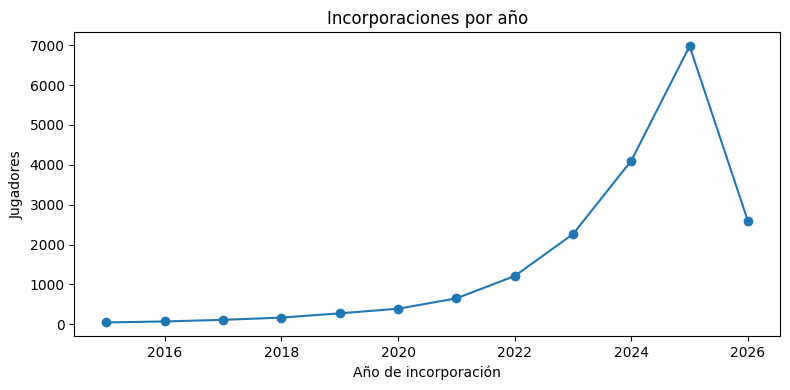

In [ ]:
por_anio[por_anio.index >= 2015].plot(kind="line", marker="o", figsize=(8, 4),
                                       title="Incorporaciones por año")
plt.xlabel("Año de incorporación")
plt.ylabel("Jugadores")
plt.tight_layout()
plt.show()

La curva sube fuerte hacia los años recientes. No es que antes hubiera menos pases: es
que el dataset guarda **el club actual** de cada jugador, así que los pases viejos sólo
sobreviven en quienes siguen en el mismo club. Una tendencia puede venir de cómo se
construyó el dato, no del fenómeno.

### Estacionalidad: incorporaciones por mes

La estacionalidad es un patrón que se repite dentro de un período fijo. Acá el período
es el año, y basta contar por mes para que aparezca.

In [ ]:
# Cuántas incorporaciones cayeron en cada mes
incorporacion.dt.month.value_counts().sort_index()

,count
club_joined_date,
1,4223
2,1440
3,439
4,229
5,224
6,878
7,7296
8,2464
9,941


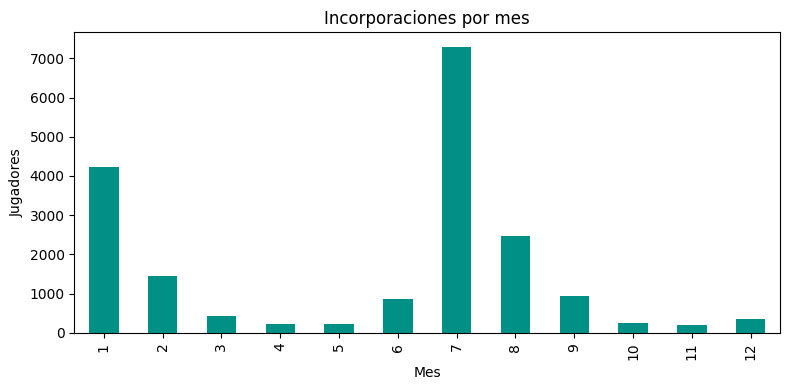

In [ ]:
incorporacion.dt.month.value_counts().sort_index().plot(kind="bar", figsize=(8, 4),
                                                        color="#009086", title="Incorporaciones por mes")
plt.xlabel("Mes")
plt.ylabel("Jugadores")
plt.tight_layout()
plt.show()

Julio concentra 7.296 incorporaciones y enero 4.223, mientras noviembre tiene 200. Son
los dos mercados de pases del calendario europeo, y aparecen en un `value_counts()` sin
que nadie tuviera que saber de fútbol para encontrarlos. Eso es estacionalidad.

### La otra fecha: contratos

El año de fin de contrato es la única columna que mira hacia adelante. También sirve
para detectar algo que no debería pasar: contratos vencidos respecto de la fecha del
snapshot.

In [ ]:
# Distribución de los años de fin de contrato
df["club_contract_valid_until_year"].value_counts().sort_index()

,count
club_contract_valid_until_year,
2025,9
2026,3251
2027,4422
2028,6056
2029,3070
2030,2026
2031,84
2032,10
2033,6


Nueve jugadores tienen contrato hasta 2025, anterior al snapshot de julio de 2026. No
es un error del pipeline: es un dato de origen que hay que decidir cómo tratar antes de
calcular cualquier «años de contrato restantes».

# Sección 6: De la exploración a las hipótesis

El análisis exploratorio no termina en un resumen: termina en **preguntas mejores que las del
principio**. Esta última fase recoge lo que apareció en el camino.

### Lo que el recorrido dejó en claro

1. **`overall` está diseñado, no observado.** Asimetría 0,01 y curtosis 0,10.
2. **Hay dos poblaciones mezcladas.** Arqueros y jugadores de campo comparten columnas con
   escalas que no se pueden promediar juntas.
3. **La relación entre nivel y valor es curva.** Pearson 0,55 contra Spearman 0,88.
4. **Los nombres de liga no identifican ligas.** 52 identificadores bajo 43 nombres.
5. **Hay ceros que son faltantes y ceros que no**, en el mismo archivo.
6. **La posición no explica el nivel ni el precio.** η² de 0,024 y 0,012.

### Las preguntas que quedaron abiertas

Cada una nació de algo que vimos, y ninguna se contesta con lo que hicimos hasta acá.

- **¿Qué variables distinguen mejor una posición de otra?** El η² las ordena de a una, pero no
  dice cómo se comportan combinadas.
- **¿`passing` y `dribbling` son la misma variable?** Correlacionan 0,86. Si lo son, darle las
  dos a un modelo es darle lo mismo dos veces.
- **¿Qué explica el valor de mercado, si no es una recta sobre el overall?** La edad y el
  contrato son candidatos que todavía no cruzamos.
- **¿Conviene analizar a los arqueros aparte o excluirlos?** Las dos respuestas son defendibles;
  la que no vale es no decidir.
- **¿La tendencia de incorporaciones por año es del fútbol o del dataset?** Sospechamos lo
  segundo, pero no lo verificamos.

### Lo que sigue

Estas cinco preguntas no son todavía hipótesis: son direcciones. Una hipótesis exige
comprometerse con una afirmación que pueda resultar falsa, decir con qué se la va a
medir, y decidir qué consecuencia tiene el resultado.

Ese paso —de la pregunta abierta a la hipótesis contrastable— es el que sigue, y es
el que se pone en juego en el TP y en la entrega del proyecto integrador.